In [1]:
import citylearn
print(f"CityLearn version: {citylearn.__version__}")

CityLearn version: 3.0.2


In [2]:
import pandas as pd
from pathlib import Path
import citylearn
from citylearn.citylearn import CityLearnEnv

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

SCHEMA = PROJECT_ROOT / "notebooks" / "data" / "schema.json"
assert SCHEMA.is_file(), f"Schema not found: {SCHEMA}"

env = CityLearnEnv(
    schema=SCHEMA,
    central_agent=False,
    random_seed=42,
)

print("CityLearn version:", citylearn.__version__)
print("Buildings:", [building.name for building in env.buildings])
print("Episode timestamps:", env.time_steps)

CityLearn version: 3.0.2
Buildings: ['Building_1', 'Building_2', 'Building_3']
Episode timestamps: 720


# Reset and inspect the observation

The Structure of the observation state is :
```
observations = [
    [...],  # Building 1
    [...],  # Building 2
    [...],  # Building 3
]
```

In [3]:
observations, info = env.reset(seed=42)

print("Current time step:", env.time_step)
print("Number of observation vectors:", len(observations))


Current time step: 0
Number of observation vectors: 3


In [4]:
building_1_state = pd.Series(
    observations[0],
    index=env.observation_names[0],
)
display(building_1_state.shape)
display(building_1_state)

(30,)

day_type                                            5.000000
hour                                                1.000000
outdoor_dry_bulb_temperature                       24.660000
outdoor_dry_bulb_temperature_predicted_1           24.910639
outdoor_dry_bulb_temperature_predicted_2           38.415958
outdoor_dry_bulb_temperature_predicted_3           27.611464
diffuse_solar_irradiance                            0.000000
diffuse_solar_irradiance_predicted_1               54.625927
diffuse_solar_irradiance_predicted_2              116.842888
diffuse_solar_irradiance_predicted_3                0.000000
direct_solar_irradiance                             0.000000
direct_solar_irradiance_predicted_1               143.324341
direct_solar_irradiance_predicted_2              1020.756104
direct_solar_irradiance_predicted_3                 0.000000
carbon_intensity                                    0.402488
indoor_dry_bulb_temperature                        23.098652
non_shiftable_load      

# Inspect the available actions

In [9]:
for building, names, space in zip(
    env.buildings,
    env.action_names,
    env.action_space,
):
    print(building.name)

    display(pd.DataFrame({
        "action": names,
        "minimum": space.low,
        "maximum": space.high,
    }))

Building_1


,action,minimum,maximum
0,dhw_storage,-1.0,1.0
1,electrical_storage,-1.0,1.0
2,cooling_device,0.0,1.0


Building_2


,action,minimum,maximum
0,dhw_storage,-1.0,1.0
1,electrical_storage,-1.0,1.0
2,cooling_device,0.0,1.0


Building_3


,action,minimum,maximum
0,dhw_storage,-1.0,1.0
1,electrical_storage,-1.0,1.0
2,cooling_device,0.0,1.0


#### The active actions are:

| Action | Meaning |
|---|---|
| `dhw_storage` | Charge or discharge domestic hot-water storage. Eg, Value = 0.091 means request to charge the domestic hot water storage by 9.1% of its storage capacity |
| `electrical_storage` | Charge or discharge the battery. Eg, Value=0.091 means request to charge the electrical battery by a normalized amount of 0.091  |
| `cooling_device` | Adjust cooling-device operation. Eg Value = 0.4 means request a cooling device control level of 0.4 (40% on its normalized action scale) |


Storage commands use positive values for charging and negative values for discharging. Cooling commands have a different meaning: they control device operation rather than storage charging.


These values are control commands, not automatically kWh or temperature setpoints. Equipment limits, state of charge, efficiency, and building conditions affect what actually happens.



# Take one step

In [10]:
from citylearn.agents.rbc import BasicRBC

agent = BasicRBC(env)
actions = agent.predict(observations, deterministic=True)

for building, names, values in zip(
    env.buildings,
    env.action_names,
    actions,
):
    print(building.name, dict(zip(names, values)))

Building_1 {'dhw_storage': 0.091, 'electrical_storage': 0.091, 'cooling_device': 0.4}
Building_2 {'dhw_storage': 0.091, 'electrical_storage': 0.091, 'cooling_device': 0.4}
Building_3 {'dhw_storage': 0.091, 'electrical_storage': 0.091, 'cooling_device': 0.4}


## Apply the step

In [11]:
next_observations, rewards, terminated, truncated, info = env.step(
    actions
)

print("New time step:", env.time_step)
print("Rewards:", rewards)
print("Terminated:", terminated)
print("Truncated:", truncated)


##--Inspect--##
before = pd.Series(observations[0], index=env.observation_names[0])
after = pd.Series(next_observations[0], index=env.observation_names[0])

variables = [
    "indoor_dry_bulb_temperature",
    "electrical_storage_soc",
    "net_electricity_consumption",
]

display(pd.DataFrame({
    "before": before[variables],
    "after": after[variables],
}))

New time step: 1
Rewards: [-0.12356949, -0.1659317, -0.012882233]
Terminated: False
Truncated: False


,before,after
indoor_dry_bulb_temperature,23.098652,22.234743
electrical_storage_soc,0.200000,0.270853
net_electricity_consumption,0.677881,1.201185


# A complete Episode


In [12]:
env = CityLearnEnv(
    schema=SCHEMA,
    central_agent=False,
    random_seed=42,
)

agent = BasicRBC(env)
observations, info = env.reset(seed=42)
terminated = truncated = False

reward_records = []

while not (terminated or truncated):
    actions = agent.predict(observations, deterministic=True)

    observations, rewards, terminated, truncated, info = env.step(
        actions
    )

    for building, reward in zip(env.buildings, rewards):
        reward_records.append({
            "time_step": env.time_step,
            "building": building.name,
            "reward": reward,
        })

Every loop iteration:
1. Reads the current observations.
2. Chooses an action for each building.
3. Advances the simulation.
4. Records the returned rewards.


RBC follows rules. Receiving rewards does not cause it to learn.
For an RL controller, learning additionally requires updating its model from transitions. CityLearn’s agent training methods and your project runners handle that process.

# Evaluate

After the episode finish:


In [13]:
kpis = env.evaluate()

display(
    kpis[["name", "level", "cost_function", "value"]]
)

,name,level,cost_function,value
0,District,district,all_time_peak_average,1.088603
1,District,district,annual_normalized_unserved_energy_total,0.017450
2,District,district,carbon_emissions_total,1.889587
3,District,district,cost_total,1.842776
4,District,district,daily_one_minus_load_factor_average,0.708263
...,...,...,...,...
64,Building_3,building,discomfort_hot_delta_maximum,3.361088
65,Building_3,building,discomfort_hot_delta_average,0.010459
66,Building_3,building,one_minus_thermal_resilience_proportion,0.200000
67,Building_3,building,power_outage_normalized_unserved_energy_total,0.739819


This uses the same evaluation interface as your existing project runners.

Note:
- Reward provides feedback during control.
- KPIs describe the resulting performance

<Axes: title={'center': 'Reward during one RBC episode'}, xlabel='time_step', ylabel='Reward'>

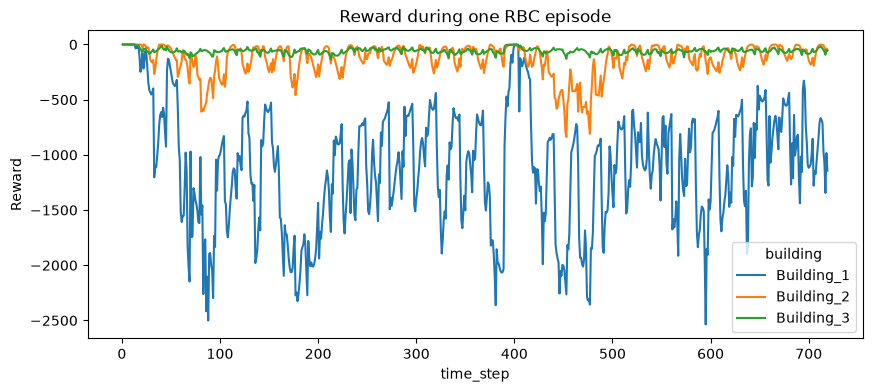

In [14]:
reward_history = pd.DataFrame(reward_records)

reward_history.pivot(
    index="time_step",
    columns="building",
    values="reward",
).plot(
    figsize=(10, 4),
    title="Reward during one RBC episode",
    ylabel="Reward",
)

# Dataset

In [5]:
from citylearn.citylearn import CityLearnEnv

dataset_name = "citylearn_challenge_2023_phase_2_local_evaluation"

env = CityLearnEnv(
    dataset_name,
    central_agent=False
)

observations, info = env.reset()

print("Number of buildings:", len(env.buildings))
print("Observation names:")
print(env.observation_names)

print("\nAction names:")
print(env.action_names)

Number of buildings: 3
Observation names:
[['day_type', 'hour', 'outdoor_dry_bulb_temperature', 'outdoor_dry_bulb_temperature_predicted_1', 'outdoor_dry_bulb_temperature_predicted_2', 'outdoor_dry_bulb_temperature_predicted_3', 'diffuse_solar_irradiance', 'diffuse_solar_irradiance_predicted_1', 'diffuse_solar_irradiance_predicted_2', 'diffuse_solar_irradiance_predicted_3', 'direct_solar_irradiance', 'direct_solar_irradiance_predicted_1', 'direct_solar_irradiance_predicted_2', 'direct_solar_irradiance_predicted_3', 'carbon_intensity', 'indoor_dry_bulb_temperature', 'non_shiftable_load', 'solar_generation', 'dhw_storage_soc', 'electrical_storage_soc', 'net_electricity_consumption', 'electricity_pricing', 'electricity_pricing_predicted_1', 'electricity_pricing_predicted_2', 'electricity_pricing_predicted_3', 'cooling_demand', 'dhw_demand', 'occupant_count', 'power_outage', 'indoor_dry_bulb_temperature_cooling_set_point'], ['day_type', 'hour', 'outdoor_dry_bulb_temperature', 'outdoor_dry_b

The `citylearn_challenge_2023_phase_2_local_evaluation` dataset contains 3 Buildings, with an episode lasting for 30 days / 720 hours (720 timesteps).

# Download Dataset for future use



In [5]:
from citylearn.data import DataSet

dataset_names = DataSet().get_dataset_names()

for name in dataset_names:
    if "2023" in name:
        print(name)

schema_path = DataSet().get_dataset(
    "citylearn_challenge_2023_phase_2_local_evaluation",
    directory="./data"
)


citylearn_challenge_2023_phase_1
citylearn_challenge_2023_phase_2_local_evaluation
citylearn_challenge_2023_phase_2_online_evaluation_1
citylearn_challenge_2023_phase_2_online_evaluation_2
citylearn_challenge_2023_phase_2_online_evaluation_3
citylearn_challenge_2023_phase_3_1
citylearn_challenge_2023_phase_3_2
citylearn_challenge_2023_phase_3_3


In [7]:
df = pd.read_csv("./data/Building_1.csv")

print(df.shape)
print(df.columns.tolist())
print(df.info())
print(df.isna().sum())
print(df.describe())
display(df.head())

(720, 16)
['month', 'hour', 'day_type', 'daylight_savings_status', 'indoor_dry_bulb_temperature', 'average_unmet_cooling_setpoint_difference', 'indoor_relative_humidity', 'non_shiftable_load', 'dhw_demand', 'cooling_demand', 'heating_demand', 'solar_generation', 'occupant_count', 'indoor_dry_bulb_temperature_cooling_set_point', 'indoor_dry_bulb_temperature_heating_set_point', 'hvac_mode']
<class 'pandas.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 16 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   month                                          720 non-null    int64  
 1   hour                                           720 non-null    int64  
 2   day_type                                       720 non-null    int64  
 3   daylight_savings_status                        720 non-null    int64  
 4   indoor_dry_bulb_temperature                    720 no

,month,hour,day_type,daylight_savings_status,indoor_dry_bulb_temperature,average_unmet_cooling_setpoint_difference,indoor_relative_humidity,non_shiftable_load,dhw_demand,cooling_demand,heating_demand,solar_generation,occupant_count,indoor_dry_bulb_temperature_cooling_set_point,indoor_dry_bulb_temperature_heating_set_point,hvac_mode
0,6,1,5,0,23.098652,-0.123570,61.086185,0.356839,0.055682,1.119216,0.0,0.0,3.0,23.222221,23.222221,1
1,6,2,5,0,22.234743,0.012520,64.361380,0.345078,0.159338,1.469638,0.0,0.0,3.0,22.222221,22.222221,1
2,6,3,5,0,22.223060,0.000838,64.493416,0.338769,0.057004,1.458372,0.0,0.0,3.0,22.222221,22.222221,1
3,6,4,5,0,22.222250,0.000029,64.769700,0.334856,0.000000,1.337342,0.0,0.0,3.0,22.222221,22.222221,1
4,6,5,5,0,22.222237,0.000014,65.152120,0.348607,0.000000,1.163453,0.0,0.0,3.0,22.222221,22.222221,1


<Axes: >

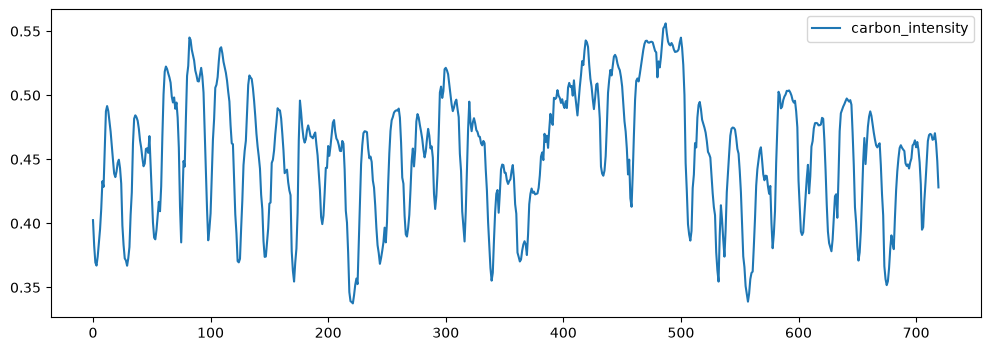

In [8]:
carbon = pd.read_csv("./data/carbon_intensity.csv")

carbon.plot(figsize=(12, 4))

Here, Carbon Intensity means "How much CO₂ is emitted for each unit of electricity taken from the grid."

Carbon Intensity changes over time because the electricity grid uses different mixes of generation sources. For example, if more low-carbon electricity is available, carbon intensity may be lower; when more fossil-fuel generation is supplying the grid, it may be higher.

For example, at low carbon intensity ( 0.35 C02/kwh), to charge battery. At high carbon intensity (0.55 co2/kwh) to dischange battery to avoid buying as much high-carbon grid electricity.

So, the design of the agent is not necessarily trying to use less electricity at all times. It may instead try to shift when electricity is drawn from the grid, so more consumption occurs during lower-carbon periods and less during higher-carbon periods.